In [ ]:
import os
import pymongo
import pandas as pd
import matplotlib.pyplot as plt
import datetime
from dotenv import load_dotenv

In [43]:
def get_sunspot_data() -> pd.DataFrame:
    """
    Connects to the local Docker MongoDB instance, 
    loads the SILSO sunspot data, and returns it 
    as a Pandas DataFrame.
    """
    
    # Load environment variables from the .env file in the project root
    load_dotenv()

    # Load connection information
    MONGO_USER = os.getenv('MONGO_USER')
    MONGO_PASS = os.getenv('MONGO_PASS')
    MONGO_DB_NAME = os.getenv('MONGO_DB_NAME')
    
    MONGO_HOST = "localhost" 
    MONGO_PORT = 27017
    
    COLLECTION_NAME = "silso_sunspot_daily" 

    client = None
    try:
        # Establish connection
        connection_string = f"mongodb://{MONGO_USER}:{MONGO_PASS}@{MONGO_HOST}:{MONGO_PORT}/"
        client = pymongo.MongoClient(connection_string, serverSelectionTimeoutMS=5000)
        
        # Test the connection
        client.server_info() 
        print(f"Successfully connected to MongoDB (Host: {MONGO_HOST}).")
        
        db = client[MONGO_DB_NAME]
        collection = db[COLLECTION_NAME]

        # Query data
        print(f"Loading data from collection: '{COLLECTION_NAME}'...")
        cursor = collection.find({}).sort("timestamp", 1)
        data = list(cursor)
        
        if not data:
            print("Warning: No data found in the collection.")
            return pd.DataFrame()

        # Convert data to Pandas DataFrame
        # Your ETL stores data in a nested structure (e.g., 'data', 'metadata')
        # pd.json_normalize is the best way to flatten this.
        df = pd.json_normalize(data, sep='_')

        # Clean up the DataFrame
        # Convert 'timestamp' to a real datetime object
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        
        # Set 'timestamp' as the index (common for time series)
        df = df.set_index('timestamp')
        
        print(f"Successfully loaded {len(df)} documents into a DataFrame.")
        return df

        
    except Exception as e:
        print(f"An unexpected error occurred: {e}")
        return pd.DataFrame()

    finally:
        # Close the connection
        if client:
            client.close()
            print("MongoDB connection closed.")

In [40]:
# Run this line to get the DataFrame
df_sunspots = get_sunspot_data()

# Display the first few rows
if not df_sunspots.empty:
    print("\nDataFrame Preview:")
    print(df_sunspots.head())

Successfully connected to MongoDB (Host: localhost).
Loading data from collection: 'silso_sunspot_daily'...
Successfully loaded 75879 documents into a DataFrame.
MongoDB connection closed.

DataFrame Preview:
                                 _id metadata_source  data_std_dev  \
timestamp                                                            
1818-01-01  69188861343719d42fba3bc1      SILSO_V2.0          -1.0   
1818-01-02  69188861343719d42fba3bc2      SILSO_V2.0          -1.0   
1818-01-03  69188861343719d42fba3bc3      SILSO_V2.0          -1.0   
1818-01-04  69188861343719d42fba3bc4      SILSO_V2.0          -1.0   
1818-01-05  69188861343719d42fba3bc5      SILSO_V2.0          -1.0   

            data_num_observations  data_indicator  data_date_fraction_year  \
timestamp                                                                    
1818-01-01                      0            True                 1818.001   
1818-01-02                      0            True                 

In [41]:
df_sunspots

,_id,metadata_source,data_std_dev,data_num_observations,data_indicator,data_date_fraction_year,data_sunspot_number
timestamp,,,,,,,
1818-01-01,69188861343719d42fba3bc1,SILSO_V2.0,-1.0,0,True,1818.001,NaN
1818-01-02,69188861343719d42fba3bc2,SILSO_V2.0,-1.0,0,True,1818.004,NaN
1818-01-03,69188861343719d42fba3bc3,SILSO_V2.0,-1.0,0,True,1818.007,NaN
1818-01-04,69188861343719d42fba3bc4,SILSO_V2.0,-1.0,0,True,1818.010,NaN
1818-01-05,69188861343719d42fba3bc5,SILSO_V2.0,-1.0,0,True,1818.012,NaN
...,...,...,...,...,...,...,...
2025-09-26,6918887e343719d42fbb6423,SILSO_V2.0,14.8,24,False,2025.736,144.0
2025-09-27,6918887e343719d42fbb6424,SILSO_V2.0,16.4,25,False,2025.738,136.0
2025-09-28,6918887e343719d42fbb6425,SILSO_V2.0,14.3,35,False,2025.741,157.0


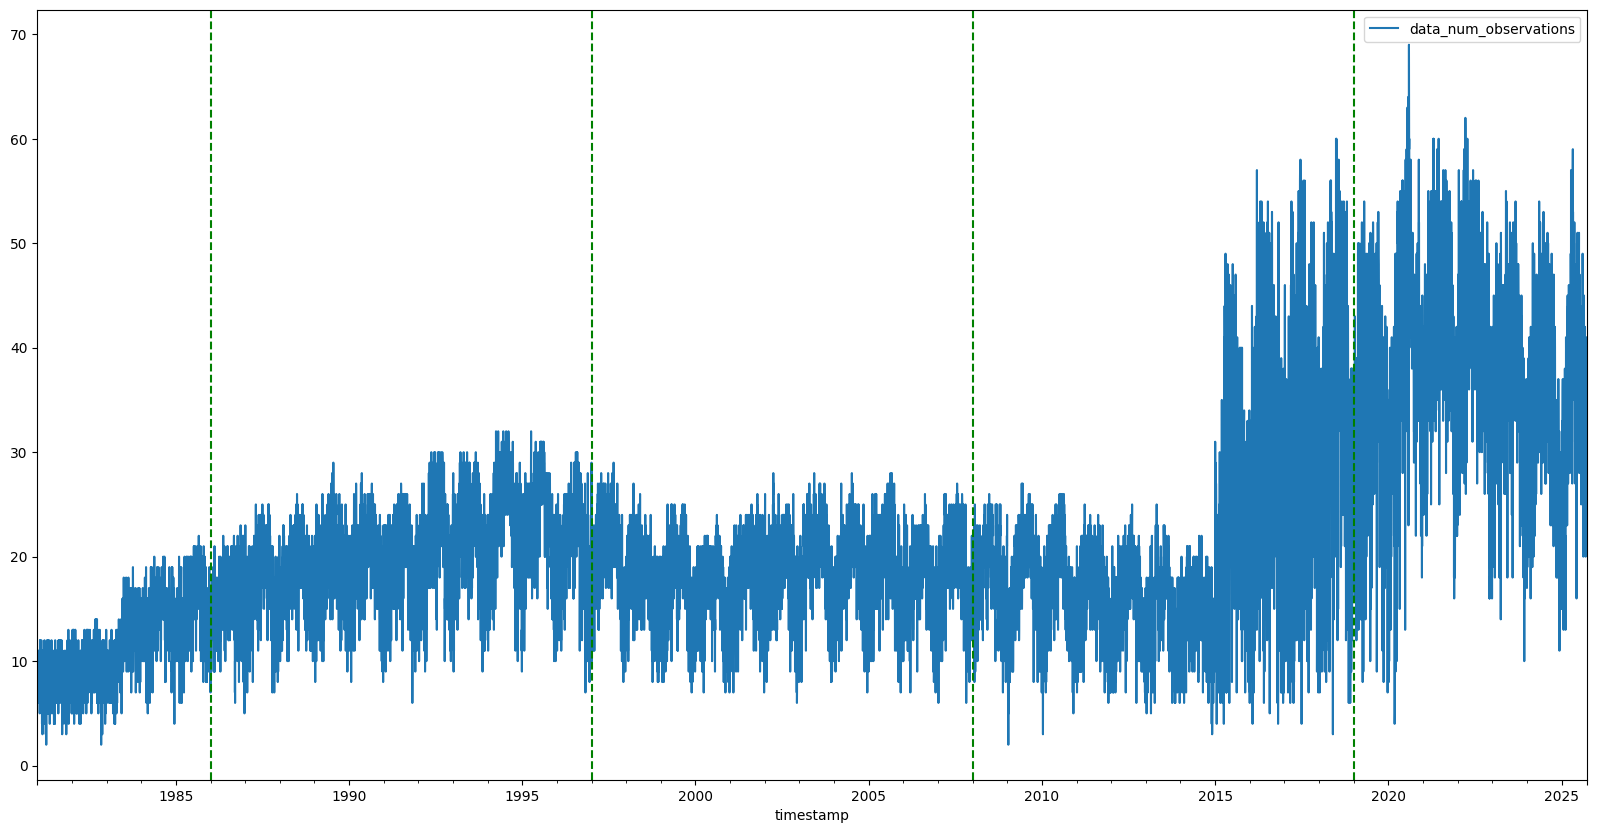

In [58]:
big_df = df_sunspots.query('data_num_observations > 1')

ax = big_df.plot(y="data_num_observations", figsize=(20, 10))
for i in range(5):
    year = 1986 + i * 11
    dt = datetime.datetime(year, 1, 1)
    ax.axvline(dt, color="green", linestyle="dashed")
plt.show()